In [1]:
!pip install -q transformers datasets accelerate scikit-learn
!pip install -q matplotlib seaborn lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, concatenate_datasets
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("PyTorch version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

MODEL_NAME = "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract"

MAX_LENGTH = 128
EPOCHS = 2
BATCH_SIZE = 16

PyTorch version: 2.14.1+cu130
GPU Available: True
Using device: cuda


In [3]:
dataset = load_dataset("ml4pubmed/pubmed-classification-20k")

print("Dataset loaded successfully!")
print(dataset)

print("\nAvailable splits:")
print(dataset.keys())

print("\nFirst few samples:")
print(dataset["train"][:5])

README.md:   0%|          | 0.00/224 [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 29.6MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv: reconstructing file:   0%|          |  0.00B / 4.96MB            

validation.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 4.92MB            

test.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/195039 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/32711 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/32634 [00:00<?, ? examples/s]

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 195039
    })
    validation: Dataset({
        features: ['label', 'text'],
        num_rows: 32711
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 32634
    })
})

Available splits:
dict_keys(['train', 'validation', 'test'])

First few samples:
{'label': ['OBJECTIVE', 'METHODS', 'METHODS', 'METHODS', 'METHODS'], 'text': ['To investigate the efficacy of 6 weeks of daily low-dose oral prednisolone in improving pain , mobility , and systemic low-grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis ( OA ) .', 'A total of 125 patients with primary knee OA were randomized 1:1 ; 63 received 7.5 mg/day of prednisolone and 62 received placebo for 6 weeks .', 'Outcome measures included pain reduction and improvement in function scores and systemic

In [4]:
if "validation" in dataset:
    data = concatenate_datasets([
        dataset["train"],
        dataset["validation"]
    ])
else:
    data = dataset["train"]

print("Total samples:", len(data))
print("Dataset columns:", data.column_names)

Total samples: 227750
Dataset columns: ['label', 'text']


In [6]:
def preprocess_text(text):
    if text is None:
        return ""

    text = text.lower()

    # Remove special symbols
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


def preprocess_example(example):
    example["text"] = preprocess_text(example["text"])
    return example


data = data.map(preprocess_example)

print("Preprocessing completed!")

print("\nOriginal dataset sample:")
print(data[0])

Map:   0%|          | 0/227750 [00:00<?, ? examples/s]

Preprocessing completed!

Original dataset sample:
{'label': 'OBJECTIVE', 'text': 'to investigate the efficacy of 6 weeks of daily low dose oral prednisolone in improving pain mobility and systemic low grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis oa'}


Dataset shape: (227750, 2)

Number of samples per label:
label
METHODS        69317
RESULTS        67794
CONCLUSIONS    31750
BACKGROUND     25176
OBJECTIVE      16215
               ...  
###26210844        1
###24629036        1
###24447459        1
###24257146        1
###24471505        1
Name: count, Length: 17503, dtype: int64


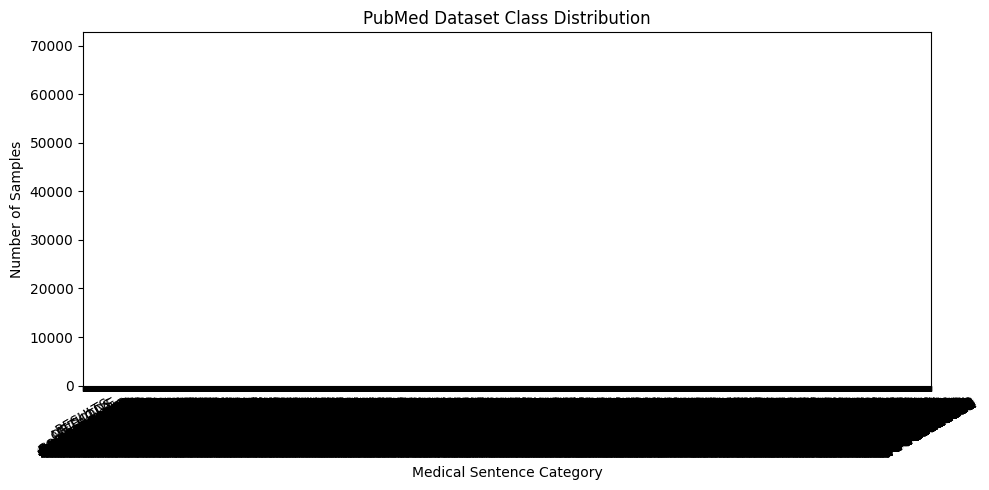


Label: OBJECTIVE
Text: to investigate the efficacy of 6 weeks of daily low dose oral prednisolone in improving pain mobility and systemic low grade inflammation in the short term and whether the effect would be sustained at 12 weeks in older adults with moderate to severe knee osteoarthritis oa

Label: METHODS
Text: a total of 125 patients with primary knee oa were randomized 1 1 63 received 7 5 mg day of prednisolone and 62 received placebo for 6 weeks

Label: METHODS
Text: outcome measures included pain reduction and improvement in function scores and systemic inflammation markers

Label: METHODS
Text: pain was assessed using the visual analog pain scale 0 100 mm

Label: METHODS
Text: secondary outcome measures included the western ontario and mcmaster universities osteoarthritis index scores patient global assessment pga of the severity of knee oa and 6 min walk distance 6mwd


In [7]:
# Convert dataset into pandas dataframe
df = data.to_pandas()

print("Dataset shape:", df.shape)

# Display label distribution
label_counts = df["label"].value_counts()

print("\nNumber of samples per label:")
print(label_counts)

# Plot class distribution
plt.figure(figsize=(10, 5))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.title("PubMed Dataset Class Distribution")
plt.xlabel("Medical Sentence Category")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# Display sample sentences
for i in range(5):
    print("\nLabel:", df.iloc[i]["label"])
    print("Text:", df.iloc[i]["text"])

In [9]:
# Define the standard clinical labels
target_labels = ["BACKGROUND", "OBJECTIVE", "METHODS", "RESULTS", "CONCLUSIONS"]

# Filter out PubMed ID header rows and only keep the valid targets
df_filtered = df[df["label"].isin(target_labels)].copy().reset_index(drop=True)

# Create label mapping
class_names = sorted(df_filtered["label"].unique())

label2id = {
    label: idx for idx, label in enumerate(class_names)
}

id2label = {
    idx: label for label, idx in label2id.items()
}

print("Label Mapping:")
print(label2id)

# Add numerical labels
df_filtered["label_id"] = df_filtered["label"].map(label2id)

# Stratified 80:20 split
train_indices, val_indices = train_test_split(
    np.arange(len(df_filtered)),
    test_size=0.20,
    random_state=42,
    stratify=df_filtered["label_id"]
)

train_df = df_filtered.iloc[train_indices].reset_index(drop=True)
val_df = df_filtered.iloc[val_indices].reset_index(drop=True)

print("\nFiltered Dataset shape:", df_filtered.shape)
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))

Label Mapping:
{'BACKGROUND': 0, 'CONCLUSIONS': 1, 'METHODS': 2, 'OBJECTIVE': 3, 'RESULTS': 4}

Filtered Dataset shape: (210252, 3)
Training samples: 168201
Validation samples: 42051


In [10]:
from datasets import Dataset

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Convert DataFrames back to Hugging Face Dataset objects
train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)

# Define tokenization function
def tokenize_function(examples):
    # Tokenize text
    tokenized = tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )
    # Map standard target key label_id to "label" expected by HF Trainer
    tokenized["label"] = examples["label_id"]
    return tokenized

# Tokenize the dataset
tokenized_train = train_dataset.map(tokenize_function, batched=True, remove_columns=train_dataset.column_names)
tokenized_val = val_dataset.map(tokenize_function, batched=True, remove_columns=val_dataset.column_names)

# Create data collator for padding to dynamic batch lengths
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("Tokenization completed successfully!")
print("Sample tokenized feature keys:", list(tokenized_train[0].keys()))

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

Map:   0%|          | 0/168201 [00:00<?, ? examples/s]

Map:   0%|          | 0/42051 [00:00<?, ? examples/s]

Tokenization completed successfully!
Sample tokenized feature keys: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [23]:
# Load sequence classification model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id
).to(device)

# Define metric computation function
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    # Calculate precision, recall, and f1 macro average
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='macro'
    )
    acc = accuracy_score(labels, predictions)

    return {
        'accuracy': acc,
        'f1': f1,
        'precision': precision,
        'recall': recall
    }

# Set up training arguments
training_args = TrainingArguments(
    output_dir="./pubmed_bert_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_steps=500,
    report_to="none"
)

# Initialize Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Model, metrics, and Trainer are successfully initialized!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

Model, metrics, and Trainer are successfully initialized!


In [12]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_data(texts):
    return tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH
    )


train_encodings = tokenize_data(
    train_df["text"].tolist()
)

val_encodings = tokenize_data(
    val_df["text"].tolist()
)

print("Tokenization completed!")

print("\nSample tokens:")
print(tokenizer.convert_ids_to_tokens(
    train_encodings["input_ids"][0][:20]
))

Tokenization completed!

Sample tokens:
['[CLS]', 'to', 'improve', 'care', 'gs', '##d', 'was', 'revised', 'for', 'adolescents', 'their', 'parents', 'and', 'interdisciplinary', 'healthcare', 'providers', 'hc', '##p', 'to', 'create']


In [13]:
class PubMedDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(value[idx])
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            int(self.labels[idx]),
            dtype=torch.long
        )

        return item


train_dataset = PubMedDataset(
    train_encodings,
    train_df["label_id"].tolist()
)

val_dataset = PubMedDataset(
    val_encodings,
    val_df["label_id"].tolist()
)

print("PyTorch datasets created successfully!")

PyTorch datasets created successfully!


In [14]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id
)

model.to(device)

print(model)
print("\nPubMedBERT classification model loaded!")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [16]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


# Reduced training settings
training_args = TrainingArguments(
    output_dir="./pubmedbert_results",

    num_train_epochs=1,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    learning_rate=2e-5,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="no",

    logging_strategy="steps",
    logging_steps=100,

    report_to="none",

    fp16=torch.cuda.is_available()
)


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)


print("Starting PubMedBERT training...")

trainer.train()

print("\nTraining completed successfully!")

Starting PubMedBERT training...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.359635,0.324530,0.883618,0.884020,0.883618,0.882338



Training completed successfully!


In [17]:
results = trainer.evaluate()

print("\nModel Evaluation Results")

for key, value in results.items():
    print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.359635,0.324530,1,0.883618,0.884020,0.883618,0.882338



Model Evaluation Results
eval_loss: 0.32453009486198425
eval_accuracy: 0.8836175120686786
eval_precision: 0.8840201487888084
eval_recall: 0.8836175120686786
eval_f1: 0.8823380357645981


In [21]:
pred_output = trainer.predict(val_dataset)

y_pred = np.argmax(
    pred_output.predictions,
    axis=1
)

y_true = np.array(val_df["label_id"])

print("\nClassification Report:\n")

# Get the correct 5 clinical label names in sorted order of their mapped IDs
active_class_names = ["BACKGROUND", "CONCLUSIONS", "METHODS", "OBJECTIVE", "RESULTS"]

print(
    classification_report(
        y_true,
        y_pred,
        target_names=active_class_names,
        zero_division=0
    )
)


Classification Report:

              precision    recall  f1-score   support

  BACKGROUND       0.71      0.81      0.76      5035
 CONCLUSIONS       0.87      0.85      0.86      6350
     METHODS       0.93      0.96      0.95     13864
   OBJECTIVE       0.76      0.57      0.65      3243
     RESULTS       0.93      0.92      0.93     13559

    accuracy                           0.88     42051
   macro avg       0.84      0.82      0.83     42051
weighted avg       0.88      0.88      0.88     42051



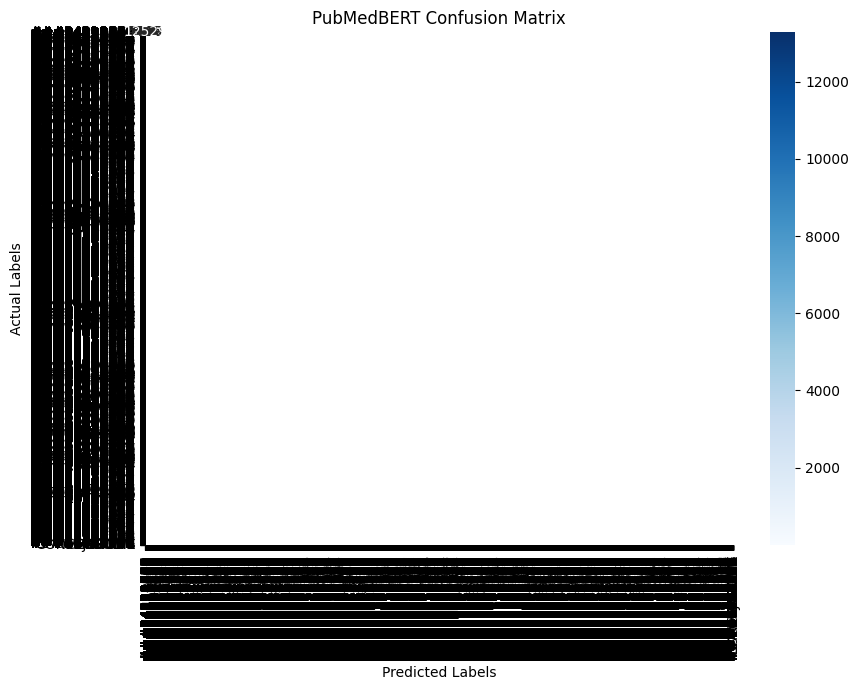

In [24]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("PubMedBERT Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.tight_layout()
plt.show()

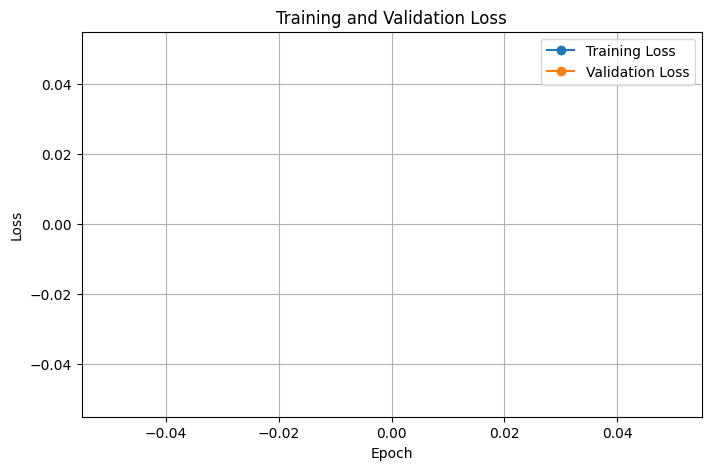

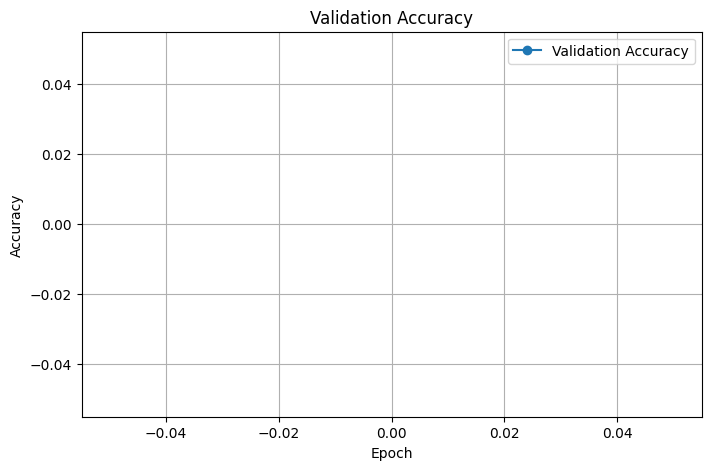

In [25]:
history = trainer.state.log_history

train_loss = [
    x["loss"] for x in history if "loss" in x
]

val_loss = [
    x["eval_loss"] for x in history if "eval_loss" in x
]

val_accuracy = [
    x["eval_accuracy"] for x in history
    if "eval_accuracy" in x
]

epochs = range(1, len(train_loss) + 1)

# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()


# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(val_accuracy) + 1),
    val_accuracy,
    marker="o",
    label="Validation Accuracy"
)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

In [26]:
from lime.lime_text import LimeTextExplainer

explainer = LimeTextExplainer(
    class_names=class_names
)

In [27]:
def predict_proba(texts):

    model.eval()

    inputs = tokenizer(
        texts,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():

        outputs = model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

    return probabilities.cpu().numpy()

Input Sentence:
comprehensive cardiac rehabilitation significantly increased vo2 uptake after exercise training to 23 0 95 confidence interval ci 20 9 22 7 vs 20 8 95 ci 18 9 22 7 ml min kg in the control group p 0 004 multiplicity p 0 015

Predicted Category: ###25370587


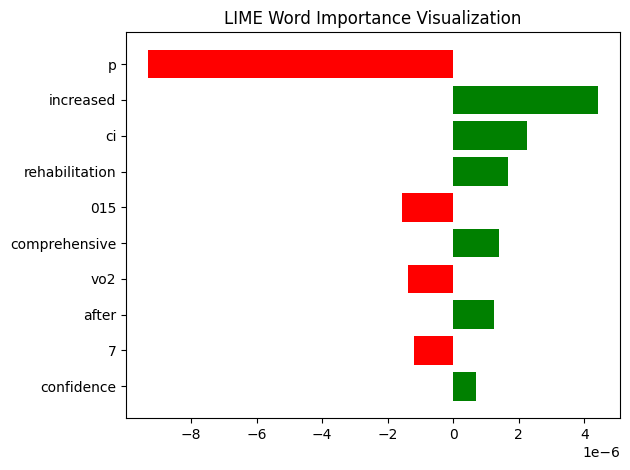

In [28]:
sample_text = val_df.iloc[0]["text"]

prediction = predict_proba([sample_text])

predicted_label = class_names[
    np.argmax(prediction[0])
]

print("Input Sentence:")
print(sample_text)

print("\nPredicted Category:", predicted_label)

explanation = explainer.explain_instance(
    sample_text,
    predict_proba,
    num_features=10,
    num_samples=500
)

# Visualize word importance
fig = explanation.as_pyplot_figure()

plt.title("LIME Word Importance Visualization")
plt.tight_layout()
plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical ar

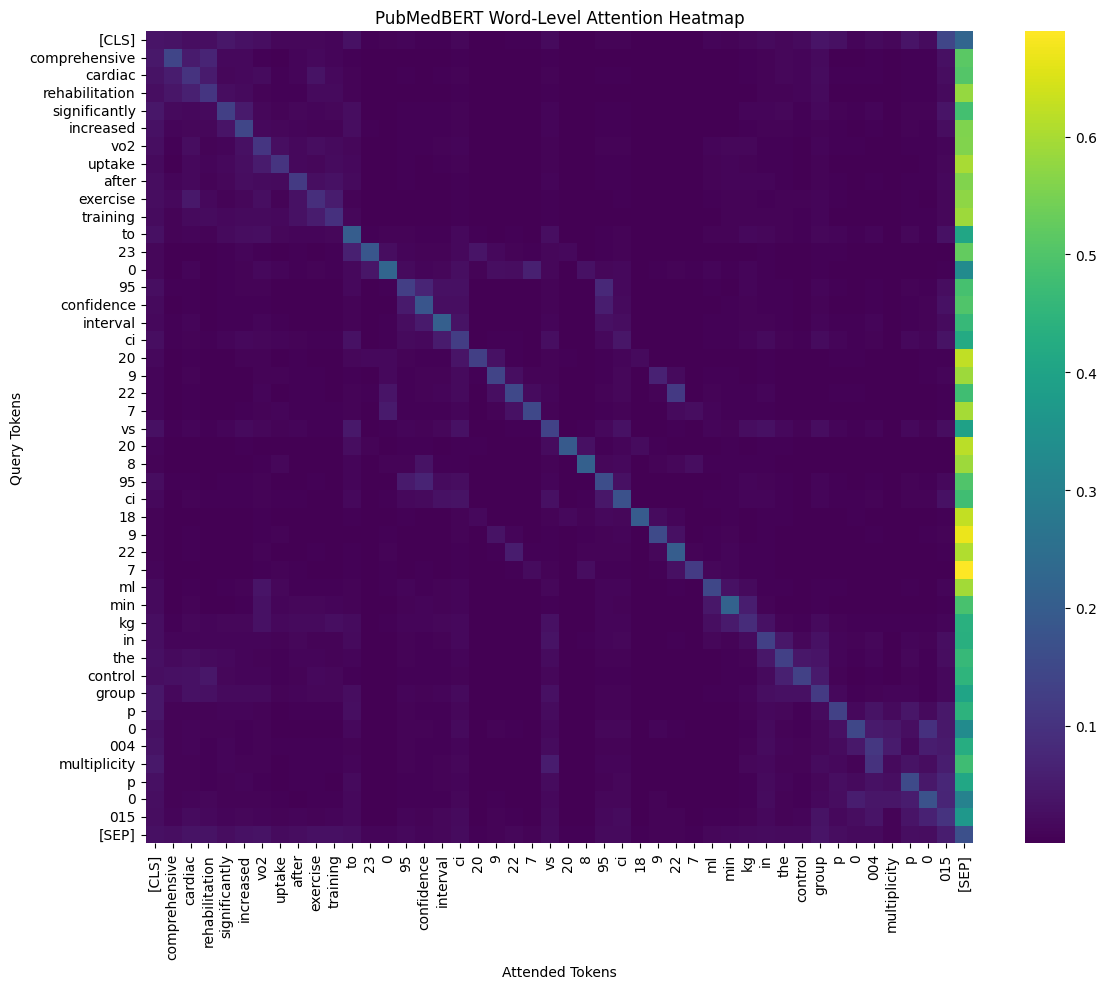

In [30]:
# Reload the model with the 'eager' attention implementation to allow outputting attentions
eager_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(active_class_names),
    id2label={i: label for i, label in enumerate(active_class_names)},
    label2id={label: i for i, label in enumerate(active_class_names)},
    attn_implementation="eager"
).to(device)

eager_model.eval()

sample_text = val_df.iloc[0]["text"]

inputs = tokenizer(
    sample_text,
    return_tensors="pt",
    truncation=True,
    max_length=MAX_LENGTH
).to(device)

with torch.no_grad():
    outputs = eager_model(
        **inputs,
        output_attentions=True
    )

# Get attention from the final transformer layer
last_attention = outputs.attentions[-1]

# Average attention across all attention heads
attention = last_attention[0].mean(dim=0)

# Convert tokens
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

attention_matrix = attention.cpu().numpy()

# Plot heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    attention_matrix,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis"
)

plt.title("PubMedBERT Word-Level Attention Heatmap")
plt.xlabel("Attended Tokens")
plt.ylabel("Query Tokens")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [31]:
def predict_medical_sentence(text):

    probabilities = predict_proba([preprocess_text(text)])

    predicted_id = np.argmax(probabilities[0])

    print("\nInput Sentence:")
    print(text)

    print("\nPredicted Label:")
    print(id2label[predicted_id])

    print("\nClass Probabilities:")

    for i, label in enumerate(class_names):
        print(
            f"{label}: {probabilities[0][i] * 100:.2f}%"
        )


test_sentence = (
    "The study evaluated the effectiveness of the treatment "
    "in patients with chronic disease."
)

predict_medical_sentence(test_sentence)


Input Sentence:
The study evaluated the effectiveness of the treatment in patients with chronic disease.

Predicted Label:
###24679362

Class Probabilities:
###24219770: 0.00%
###24219814: 0.01%
###24219842: 0.00%
###24219852: 0.00%
###24219882: 0.01%
###24219891: 0.00%
###24220044: 0.00%
###24220251: 0.00%
###24220254: 0.01%
###24220287: 0.01%
###24220326: 0.01%
###24220342: 0.00%
###24220352: 0.01%
###24220376: 0.01%
###24220487: 0.01%
###24220504: 0.00%
###24220555: 0.01%
###24220602: 0.00%
###24220616: 0.00%
###24220660: 0.00%
###24220704: 0.01%
###24220723: 0.01%
###24220914: 0.00%
###24220935: 0.00%
###24221391: 0.01%
###24221463: 0.01%
###24221533: 0.01%
###24221577: 0.00%
###24221838: 0.00%
###24221839: 0.01%
###24221841: 0.00%
###24222009: 0.01%
###24222194: 0.01%
###24222323: 0.01%
###24222372: 0.00%
###24222526: 0.01%
###24222666: 0.01%
###24222836: 0.01%
###24222837: 0.01%
###24222839: 0.00%
###24223416: 0.01%
###24223740: 0.01%
###24223806: 0.01%
###24224396: 0.00%
###242

In [32]:
model.save_pretrained("./PubMedBERT_Model")
tokenizer.save_pretrained("./PubMedBERT_Model")

print("Model and tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully!
